# Part I · Cleaning with `clean_listings.py`

**Analysis question:** How does the nightly price of Airbnb listings in London vary? Before the analysis we need a table with a valid price, no duplicates and explained missing values.

The original dataset is not modified.

## Loading and cleaning

`load_dataset()` reads the file, and `clean_dataset()` cleans the data and returns the cleaned table together with the list of steps. The dataset path is taken from the environment variable `PVDH_DATASET_PATH`; if it is not set, `dataset/listings.csv.gz` is used.

In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "scripts" / "clean_listings.py").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.clean_listings import clean_dataset, load_dataset, missing_value_table

DATA_PATH = Path(os.environ.get("PVDH_DATASET_PATH", ROOT / "dataset" / "listings.csv.gz"))
assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"
raw = load_dataset(DATA_PATH)
cleaned, steps = clean_dataset(raw)
print(f"Source: {DATA_PATH.name} | before: {len(raw):,} rows × {raw.shape[1]} columns | after: {len(cleaned):,} rows × {cleaned.shape[1]} columns")

Source: listings.csv.gz | before: 91,954 rows × 90 columns | after: 59,846 rows × 78 columns


## 1. Cleaning steps

Each step shows what was done and why. The numbers are computed from the data, not typed by hand.

In [2]:
for number, step in enumerate(steps, start=1):
    print(f"{number}. {step}")

1. Dropped 14 completely empty columns, because they hold no information: neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, calendar_updated, license, instant_bookable. bathrooms is kept, because it is rebuilt from bathrooms_text.
2. Removed 0 duplicate listings (same id).
3. Converted price from text such as '$1,180.00' to a number by removing the '$' and the thousands commas.
4. Dropped 32,049 rows without a price. Price is the main variable for analysis, so filling it in would invent the values we want to study. These listings are mostly not bookable: 87% have no available days in the next year (against 0.5% of the listings with a price), and 93% have source = 'previous scrape'.
5. Dropped 59 rows with a price above the 99.9th percentile of their own room type (Entire home/apt 6,798, Hotel room 1,440, Priva

## 2. Before and after

The table summarises the size of the data. The chart shows how many rows were kept and why the others were removed: listings without a price, listings with an extreme price (above the 99.9th percentile of their room type) and duplicated IDs. The axis is logarithmic because there are far more kept rows than removed ones.

,before,after
rows,91954,59846
columns,90,78
missing cells,1933263,215027


,rows
kept,59846
removed: no price,32049
removed: extreme price,59
removed: duplicated ID,0


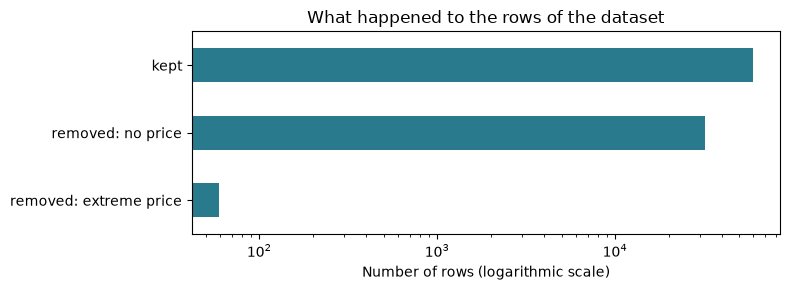

In [3]:
summary = pd.DataFrame(
    {
        "before": [len(raw), raw.shape[1], int(raw.isna().sum().sum())],
        "after": [len(cleaned), cleaned.shape[1], int(cleaned.isna().sum().sum())],
    },
    index=["rows", "columns", "missing cells"],
)
display(summary)

duplicate = raw["id"].duplicated()
dropped = raw.loc[~raw.index.isin(cleaned.index) & ~duplicate]
no_price = dropped["price"].isna()
fate = pd.Series(
    {
        "kept": len(cleaned),
        "removed: no price": int(no_price.sum()),
        "removed: extreme price": int((~no_price).sum()),
        "removed: duplicated ID": int(duplicate.sum()),
    }
)
assert fate.sum() == len(raw), "Every row must be either kept or removed"
display(fate.to_frame("rows"))
ax = fate[fate.gt(0)].sort_values().plot.barh(figsize=(8, 3), color="#287a8c")
ax.set(xscale="log", xlabel="Number of rows (logarithmic scale)", title="What happened to the rows of the dataset")
plt.tight_layout()
plt.show()

## 3. Missing values by column

The `action` column shows what cleaning did to each column that had missing values:

- `column dropped`: the column was completely empty and was removed;
- `filled`: the missing values were filled in (see the steps above for how);
- `rows dropped`: the missing values were only in rows that were removed;
- `kept missing`: the missing values were left empty on purpose, e.g. the review scores of listings without reviews.

,columns
action,
column dropped,14
filled,5
kept missing,22
rows dropped,10


,missing_before,missing_after,action
source,59643,57266.0,kept missing
description,701,228.0,kept missing
host_location,22885,17689.0,kept missing
host_about,42695,27620.0,kept missing
bathrooms_text,108,92.0,kept missing
price_quote_total_price,32193,144.0,kept missing
price_quote_price_per_night,32193,144.0,kept missing
minimum_nights,309,298.0,kept missing
maximum_nights,309,298.0,kept missing
minimum_minimum_nights,309,298.0,kept missing


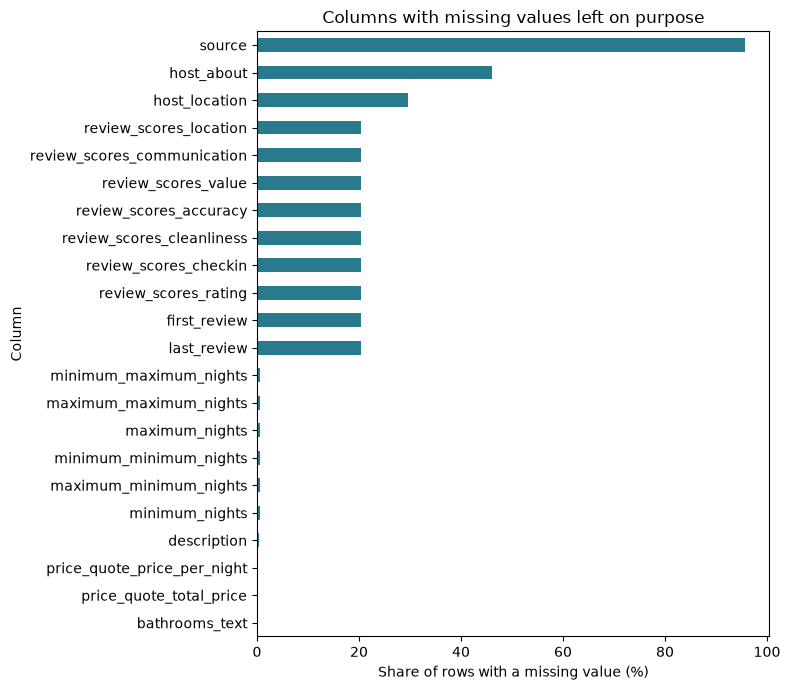

In [4]:
missing = missing_value_table(raw, cleaned)
display(missing.groupby("action").size().to_frame("columns"))
display(missing[missing["action"].eq("kept missing")])

kept = missing[missing["action"].eq("kept missing")]
ax = (kept["missing_after"] / len(cleaned) * 100).sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
ax.set(xlabel="Share of rows with a missing value (%)", ylabel="Column", title="Columns with missing values left on purpose")
plt.tight_layout()
plt.show()

## 4. Extreme prices

A normal price for an entire home can be an error for a single room, so the limit is the 99.9th percentile of **each room type**. Below: how many rows were removed for each type, 10 of the removed rows, and the highest price that remained for each type.

In [5]:
extreme = dropped[~no_price]
display(extreme["room_type"].value_counts().to_frame("removed"))
display(extreme[["id", "room_type", "accommodates", "price"]].head(10))
display(cleaned.groupby("room_type")["price"].max().to_frame("highest price kept"))

,removed
room_type,
Entire home/apt,40
Private room,18
Shared room,1


,id,room_type,accommodates,price
1808,4759397,Shared room,8,"$2,369.00"
4369,9470827,Private room,1,"$8,000.00"
5867,10475894,Private room,2,"$8,693.00"
9263,13254774,Private room,1,"$75,000.00"
12490,18344241,Private room,2,"$5,100.00"
17481,24521822,Entire home/apt,8,"$9,300.00"
24891,39798147,Entire home/apt,2,"$10,000.00"
24902,39798184,Entire home/apt,2,"$8,000.00"
24903,39798187,Entire home/apt,2,"$8,000.00"
24904,39798190,Entire home/apt,2,"$8,000.00"


,highest price kept
room_type,
Entire home/apt,6798.4
Hotel room,1440.0
Private room,5000.0
Shared room,622.5


## 5. Final checks

All values below must be 0. If any of them is not, cleaning has left a problem.

In [6]:
checks = pd.Series(
    {
        "missing price": int(cleaned["price"].isna().sum()),
        "price <= 0": int(cleaned["price"].le(0).sum()),
        "duplicated IDs": int(cleaned["id"].duplicated().sum()),
        "missing bathrooms, bedrooms or beds": int(cleaned[["bathrooms", "bedrooms", "beds"]].isna().sum().sum()),
        "missing reviews_per_month": int(cleaned["reviews_per_month"].isna().sum()),
    }
)
display(checks.to_frame("count"))
assert checks.eq(0).all(), "Problems remain after cleaning"

,count
missing price,0
price <= 0,0
duplicated IDs,0
"missing bathrooms, bedrooms or beds",0
missing reviews_per_month,0


## 6. Saving the result

This notebook does not write any files. To save the cleaned table (`dataset/listings_clean.csv`) and the full report (`reports/listings_cleaning.txt`), run this from the project root:

```
python scripts/clean_listings.py dataset/listings.csv.gz
```